# ADP 모의고사 3회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: 모의고사 3.ipynb

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'모의고사/3회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 매장 매출 설명

매장 컨설턴트는 Urban(Yes/No)별 Sales와 가격·소득·광고 등의 관계를 살피려 한다. 매장은 독립 표본이며 두 집단의 매출은 정규성을 만족한다고 가정한다. 모분산의 동일성은 주어지지 않았다.

자료: Carseats.csv

### 1-1

도시 매장과 비도시 매장의 평균 매출이 다른지 유의수준 5%에서 판단하시오. 검정 선택 근거·가정·가설·통계량·p-value·기각 여부와 매장 운영 맥락의 결론을 제시하시오.

**판단 및 풀이 근거**

독립 두 집단의 정규 평균 비교이며 모분산 동일성은 알려져 있지 않아 Welch t검정을 선택한다. H0: μ도시=μ비도시, H1: μ도시≠μ비도시. 분산 검정 결과로 유리한 평균 검정을 사후 선택하지 않는다.

**계산·해석 상세**

두 집단은 독립입니다. 정규성 가정 하 Bartlett을 보고, 등분산 여부와 무관하게 Welch를 사용한 선택 근거를 명시합니다. 귀무가설을 “채택/증명”하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [2]:
set_question('1-1')
car=load('Carseats.csv');a=car.loc[car.Urban=='Yes','Sales'];b_=car.loc[car.Urban=='No','Sales']
print('Bartlett:',stats.bartlett(a,b_));print('Welch t-test:',stats.ttest_ind(a,b_,equal_var=False))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_w=stats.ttest_ind(a,b_,equal_var=False)
_va=a.var(ddof=1)/len(a);_vb=b_.var(ddof=1)/len(b_)
_df=(_va+_vb)**2/(_va**2/(len(a)-1)+_vb**2/(len(b_)-1))
report_test('Welch 독립 두 표본 t','도시/비도시 평균 매출이 같다','도시/비도시 평균 매출이 다르다',_w.statistic,_w.pvalue,'도시 여부에 따라 평균 매출이 다르다','독립 매장·집단별 정규성 가정·등분산 불필요. 지역의 인과 효과로 단정하지 않음.',df=_df)

Bartlett: BartlettResult(statistic=np.float64(0.35574228007062925), pvalue=np.float64(0.5508804259216197))
Welch t-test: TtestResult(statistic=np.float64(0.4907940792616884), pvalue=np.float64(0.6239472137614593), df=np.float64(286.94881572070454))
{
  "question": "1-1",
  "method": "Welch 독립 두 표본 t",
  "H0": "도시/비도시 평균 매출이 같다",
  "H1": "도시/비도시 평균 매출이 다르다",
  "statistic": 0.4907940792616884,
  "p_value": 0.6239472137614593,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 매장·집단별 정규성 가정·등분산 불필요. 지역의 인과 효과로 단정하지 않음.",
  "conclusion": "귀무가설을 기각하지 못한다. 도시 여부에 따라 평균 매출이 다르다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "df": 286.94881572070443
}


### 1-2

Sales와 CompPrice·Income·Advertising·Population·Price·Age·Education의 선형 관계를 평가하시오. 관계의 방향·크기·가설·p-value·기각 여부를 제시하고 다중 탐색과 비선형성의 한계를 설명하시오.

**판단 및 풀이 근거**

연속 변수의 선형 관계를 Pearson으로 평가한다. 각 H0: rho=0, H1: rho≠0이며 상관 크기와 Holm 보정 p값을 구분한다. 명목 범주 코드에 수치 간격 의미를 부여하지 않는다.

**계산·해석 상세**

전체 상관행렬과 Sales에 대한 개별 r·p값을 보고합니다. 피어슨 상관이 낮다고 비선형 관계까지 없다는 뜻은 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

    feature         r      p_value
  CompPrice  0.009739 8.666009e-01
     Income  0.570908 2.406563e-27
Advertising  0.409674 1.433849e-13
 Population  0.039799 4.922472e-01
      Price -0.619604 3.366489e-33
        Age  0.003003 9.586883e-01
  Education -0.056047 3.333087e-01


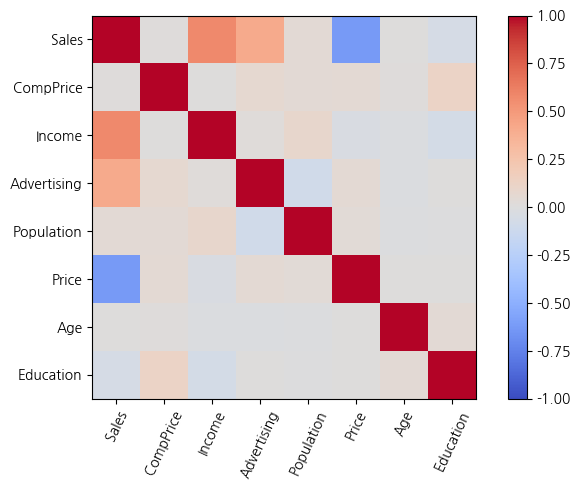

{
  "question": "1-2",
  "method": "Pearson 선형 상관: CompPrice",
  "H0": "rho(Sales,CompPrice)=0",
  "H1": "rho(Sales,CompPrice) != 0",
  "statistic": 0.009738616458626049,
  "p_value": 0.8666009066431143,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각하지 못한다. Sales와 CompPrice 사이에 선형 관계가 있다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "adjusted_p_value": 1.0,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-2",
  "method": "Pearson 선형 상관: Income",
  "H0": "rho(Sales,Income)=0",
  "H1": "rho(Sales,Income) != 0",
  "statistic": 0.5709083087410602,
  "p_value": 2.4065631098835393e-27,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각한다. Sales와 Income 사이에 선형 관계가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 1.4439378659301237e-26,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-2",
  "method": "Pearson 선형 상관: Adv

In [3]:
set_question('1-2')
numeric_correlations(car,'Sales',['CompPrice','Income','Advertising','Population','Price','Age','Education'])

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_correlations(car,'Sales',['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education'])

### 1-3

위 특성을 후보로 매출 설명 모형을 구성하시오. 전체 후보에서 불필요한 변수를 제거하는 선택 기준·과정·최종 회귀식을 제시하고 연관과 인과를 구분하시오.

**판단 및 풀이 근거**

후진제거를 AIC 개선으로 정의합니다. 선택된 계수·절편으로 회귀식을 제시합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('1-3')
car_model=select_ols(car,'Sales',['CompPrice','Income','Advertising','Population','Price','Age','Education'],'backward');print('회귀식 계수:',car_model.params.to_dict())

선택 변수: ['Income', 'Advertising', 'Population', 'Price']
   step                                           features         AIC
0     1  Income,Advertising,Population,Price,Age,Education  555.767120
1     2            Income,Advertising,Population,Price,Age  554.488057
2     3                Income,Advertising,Population,Price  553.928824
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.876
Model:                            OLS   Adj. R-squared:                  0.875
Method:                 Least Squares   F-statistic:                     522.5
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          1.69e-132
Time:                        09:51:52   Log-Likelihood:                -271.96
No. Observations:                 300   AIC:                             553.9
Df Residuals:                     295   BIC:                             572.4
Df Model:                   

## 2. 구매 고객 세분화

별도 BlackFriday 거래 자료로 유사 구매 특성을 가진 고객을 분류하려 한다. 이 대문항의 전처리·거리 계산·집단 해석은 같은 행과 변수 정의를 공유한다.

자료: BlackFriday.csv

### 2-1

Product_Category_2/3의 미기재를 0으로 표시하고 세 카테고리 코드 합 Product_all을 만들되 크기의 의미를 검토하시오. ID는 문자열, Occupation·Marital_Status·상품코드는 범주형으로, Gender·Age·City_Category·Stay_In_Current_City_Years는 더미로 구성하시오.

**판단 및 풀이 근거**

범주 코드의 합 Product_all은 문제 지시상 생성하며 거리 특성에서는 제외합니다. 고유 ID도 거리·의미를 갖지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [5]:
set_question('2-1')
black=load('BlackFriday.csv');black[['Product_Category_2','Product_Category_3']]=black[['Product_Category_2','Product_Category_3']].fillna(0)
black['Product_all']=black[['Product_Category_1','Product_Category_2','Product_Category_3']].sum(axis=1)
black['User_ID']=black.User_ID.astype(str)
for c in ['Occupation','Marital_Status','Product_Category_1','Product_Category_2','Product_Category_3']:black[c]=black[c].astype('category')
black1=pd.concat([black,pd.get_dummies(black[['Gender','Age','City_Category','Stay_In_Current_City_Years']],prefix=['Gender','Age','City','Stay'])],axis=1)
print(black1.head())

  User_ID Product_ID Occupation Marital_Status  ... Stay_0 Stay_1 Stay_2 Stay_4+
0      34        P24          9              0  ...  False  False  False    True
1       4         P9          7              1  ...   True  False  False   False
2       7        P22          4              0  ...  False   True  False   False
3      12        P26          9              0  ...   True  False  False   False
4      93        P24          9              0  ...  False  False  False    True

[5 rows x 25 columns]


### 2-2

User_ID·Product_ID·원래 Gender/Age/City/Stay 열·Product_all을 거리 입력에서 제외하시오. 남은 값을 수치로 표현·표준화해 k=2~5 집단을 비교하고 집단 수를 선택하시오. 명목 코드 거리의 한계를 설명하시오.

**판단 및 풀이 근거**

범주형의 수치 변환을 요청대로 코드값으로 수행하나 명목 코드 간 거리는 임의입니다. 원핫·혼합거리 대안도 설명합니다. 표준화 후 2~5개 k의 silhouette·inertia를 비교합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

   k  silhouette      inertia
0  2    0.110857  9580.115623
1  3    0.124678  8958.949597
2  4    0.099806  8512.546872
3  5    0.113171  7999.004601


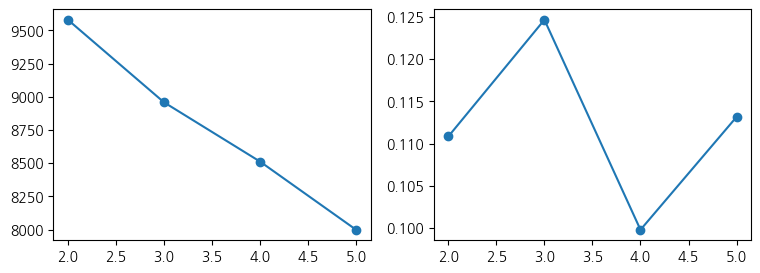

          Purchase  Product_all  clust
clust                                 
0      2533.089700     7.034653    0.0
1      2379.992693     6.835821    1.0
2      2527.265019     6.934010    2.0


In [6]:
set_question('2-2')
exclude=['User_ID','Product_ID','Gender','Age','City_Category','Stay_In_Current_City_Years','Product_all']
cluster_X=black1.drop(columns=exclude).copy()
for c in cluster_X.columns:cluster_X[c]=cluster_X[c].astype(float)
black_cluster,k_table=cluster(cluster_X,OUT,original=black)

### 2-3

선택한 집단 번호를 원자료의 같은 행에 clust로 연결해 CSV를 저장하시오. 집단별 Gender·Age·Purchase 분포로 고객 특성과 활용 방안을 설명하시오.

**판단 및 풀이 근거**

원 입력 행 순서를 유지해 clust를 붙이고 앞 셀에서 CSV를 저장했습니다. 군집 번호는 순위·타깃 라벨이 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [7]:
set_question('2-3')
print(pd.crosstab(black_cluster.clust,black_cluster.Gender));print(pd.crosstab(black_cluster.clust,black_cluster.Age));print(black_cluster.groupby('clust').Purchase.agg(['count','mean','median']))

Gender    F    M
clust           
0        99  103
1       100  101
2       109   88
Age    18-25  26-35  36-45
clust                     
0         65     61     76
1         66     60     75
2         58     68     71
       count         mean       median
clust                                 
0        202  2533.089700  2496.027129
1        201  2379.992693  2416.910387
2        197  2527.265019  2492.250727


## 3. 블로그 반응 요약

별도 댓글·날짜·품사 사전으로 블로그 반응을 요약한다. 전체 댓글의 형용사와 2월 댓글의 명사를 구분해 분석하려 한다.

자료: comments.csv + lexicon.csv

### 3-1

숫자·특수문자를 정제하되 문서 ID와 날짜를 보존하시오. 원문·정제 결과의 대응을 확인하시오.

**판단 및 풀이 근거**

숫자·특수 문자 제거 뒤 문서 ID와 날짜를 유지합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [8]:
set_question('3-1')
comments=load('comments.csv');lexicon=load('lexicon.csv');comments['clean']=comments.text.map(clean_text);print(comments.head())

         date                          text                  clean
0  2026-01-15  호텔 여행 배송 행복 영화 호텔 즐겁다 123 !@  호텔 여행 배송 행복 영화 호텔 즐겁다
1  2026-01-16  배송 공구 배송 영화 영화 호텔 편하다 123 !@  배송 공구 배송 영화 영화 호텔 편하다
2  2026-01-17   가족 공구 맛 여행 공구 여행 편하다 123 !@   가족 공구 맛 여행 공구 여행 편하다
3  2026-01-18  공구 배송 여행 배송 가족 가족 즐겁다 123 !@  공구 배송 여행 배송 가족 가족 즐겁다
4  2026-01-19  학교 공구 여행 배송 여행 배송 빠르다 123 !@  학교 공구 여행 배송 여행 배송 빠르다


### 3-2

동봉 사전에 형용사로 등록된 어휘를 추출하고 빈도를 요약하시오. 사전 등재와 단순 빈도 추출을 구분하시오.

**판단 및 풀이 근거**

등록 단어와 POS의 대응을 명시합니다. 단순 토큰을 임의로 형용사라 부르지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

[['즐겁다'], ['편하다'], ['편하다'], ['즐겁다'], ['빠르다'], ['편하다'], ['즐겁다'], ['즐겁다'], ['즐겁다'], ['좋다']]
  word  count
0  즐겁다     17
1   좋다     15
2  편하다     14
3  빠르다     14


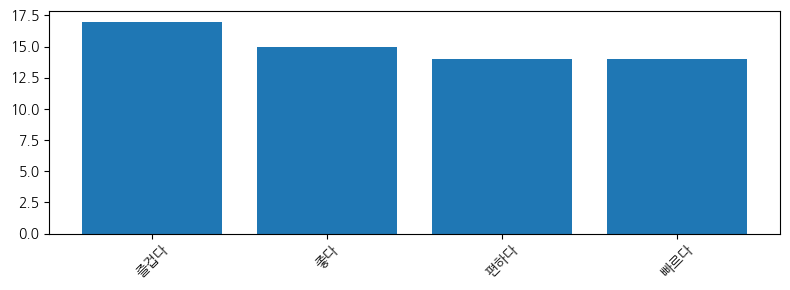

In [9]:
set_question('3-2')
adjectives=lexical_pos(comments.text,lexicon,'Adjective');print(adjectives[:10]);word_plot(adjectives,10)

### 3-3

날짜를 파싱해 2월 댓글만 선택하고 명사 빈도를 시각화하시오. 전체 댓글 분석과 결과가 달라질 수 있는 이유를 설명하시오.

**판단 및 풀이 근거**

전체 댓글의 단어 빈도가 아니라 2월 댓글을 먼저 필터링합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

  word  count
0   공구     35
1   학교     22
2   행복     20
3   호텔     17
4   배송     16
5   가족     15
6    맛     15
7   여행     14
8   영화     14


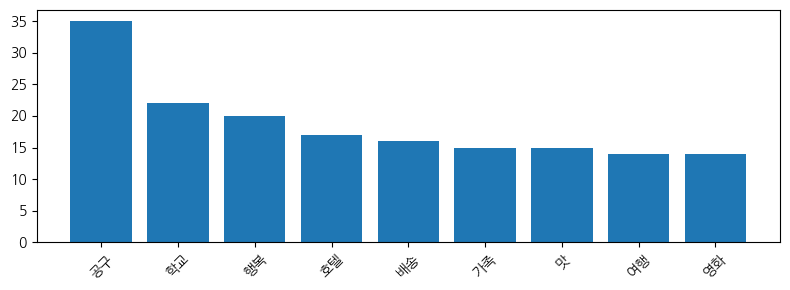

In [10]:
set_question('3-3')
feb=comments[pd.to_datetime(comments.date).dt.month==2];assert len(feb)>0;word_plot(lexical_pos(feb.text,lexicon,'Noun'),20)